In [1]:
import hashlib, pandas as pd
from pathlib import Path

DATA = Path("Data")
STRESS_IDS = ["p03", "p04", "p19"]

def md5(p): 
    return hashlib.md5(p.read_bytes()).hexdigest()

# 1) Which splits are these students in, in each main dataset?
for ds in sorted(DATA.glob("AI-for-Vision-Dataset*")):
    f = ds / "labels" / "labels.csv"
    if not f.exists():
        continue
    df = pd.read_csv(f, dtype=str)
    df["student"] = df["form_id"].str.split("-").str[0]
    sub = df[df["student"].isin(STRESS_IDS)]
    print(ds.name)
    print(sub.groupby(["student", "split"]).size(), "\n")

# 2) Are the stress images identical files to ones in the main data?
stress = {md5(p): p for p in (DATA / "stress").rglob("*") 
          if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
for ds in sorted(DATA.glob("AI-for-Vision-Dataset*")):
    for sid in STRESS_IDS:
        for p in (ds / "images" / sid).glob("*.*") if (ds / "images" / sid).exists() else []:
            if md5(p) in stress:
                print("IDENTICAL:", p, "==", stress[md5(p)])

AI-for-Vision-Dataset-3
student  split
p03      train    10
p04      test     10
p19      train    10
dtype: int64 



In [2]:
for ds in sorted(DATA.glob("AI-for-Vision-Dataset*")):
    print("=====", ds.name)
    for p in sorted(ds.rglob("*")):
        if p.is_file() and p.suffix.lower() in {".csv", ".md", ".json"} and "json" not in p.parent.name:
            print("  ", p.relative_to(ds))
    imgs = [p for p in ds.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    print("   images:", len(imgs))
    print("   student folders:", sorted({p.parent.name for p in imgs})[:8], "...")

===== AI-for-Vision-Dataset
   roster.csv
   images: 725
   student folders: ['p01', 'p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08'] ...
===== AI-for-Vision-Dataset-2
   README.md
   images: 728
   student folders: ['p01', 'p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08'] ...
===== AI-for-Vision-Dataset-3
   labels/images.csv
   labels/labels.csv
   images: 731
   student folders: ['p01', 'p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08'] ...


In [3]:
import sys; sys.path.insert(0, "src")
import importlib, s3231_data as data
importlib.reload(data)

main, stress = data.load_all()
print(main.groupby("split").agg(images=("path", "size"), forms=("form_id", "nunique")))
print(main.groupby(["split", "kind"]).size().unstack())
print("stress images:", len(stress), "| matched to labels:", stress["split"].notna().sum())

images: 2184 | duplicate filenames dropped: 0 | unparsed filenames: 0 | images without labels: 0
       images  forms
split               
test      398    140
train    1249    420
val       447    150
kind   hard  photo  scan
split                   
test    138    131   129
train   416    409   424
val     148    149   150
stress images: 90 | matched to labels: 90


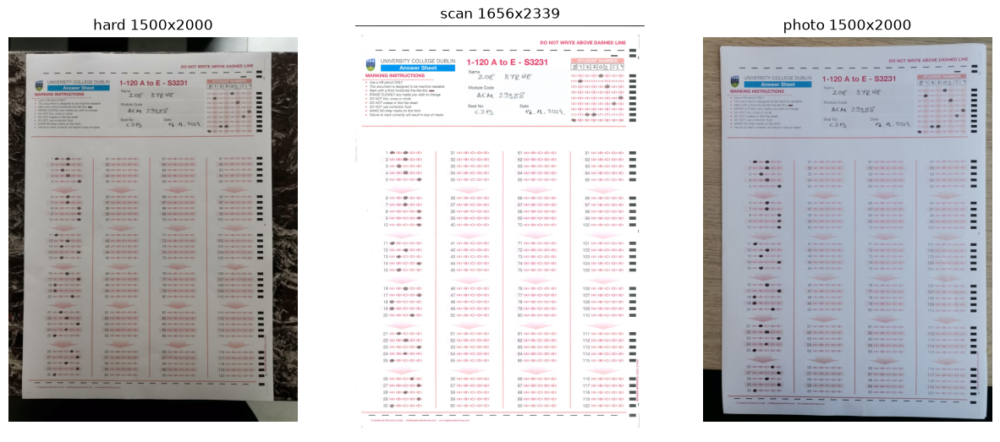

p07-f03 {'n_answered': '30', 'tool': 'pencil', 'style': 'fill', 'student_number': '81770254'}


In [4]:
import cv2, numpy as np, matplotlib.pyplot as plt
tr = main[main.split == "train"]
fid = tr.form_id.iloc[0]
ex = tr[tr.form_id == fid]
fig, axes = plt.subplots(1, len(ex), figsize=(5 * len(ex), 7))
for ax, (_, r) in zip(np.atleast_1d(axes), ex.iterrows()):
    im = cv2.imread(r.path)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r.kind} {im.shape[1]}x{im.shape[0]}"); ax.axis("off")
plt.show()
print(fid, main[main.form_id == fid].iloc[0][["n_answered", "tool", "style", "student_number"]].to_dict())

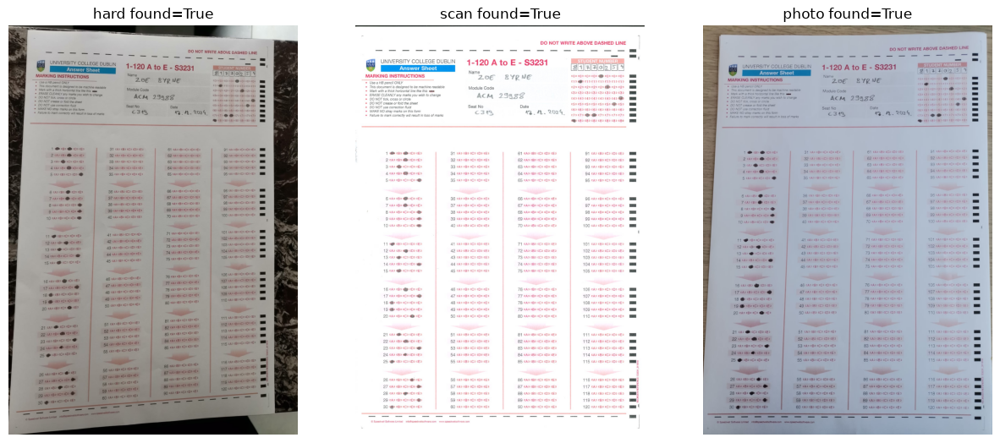

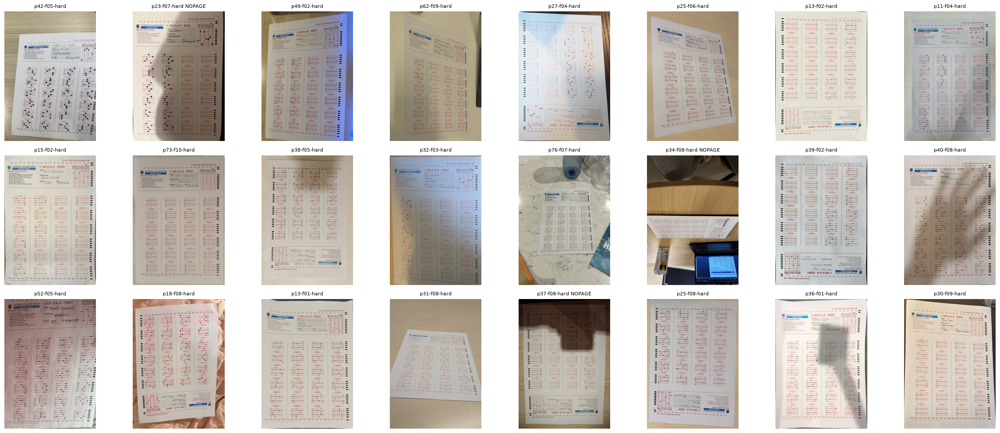

In [5]:
import sys; sys.path.insert(0, "src")
import importlib, align; importlib.reload(align)
import cv2, numpy as np, matplotlib.pyplot as plt

tr = main[main.split == "train"]
ex = tr[tr.form_id == tr.form_id.iloc[0]]
fig, axes = plt.subplots(1, len(ex), figsize=(5 * len(ex), 7))
for ax, (_, r) in zip(np.atleast_1d(axes), ex.iterrows()):
    page, info = align.warp_sheet(cv2.imread(r.path))
    ax.imshow(cv2.cvtColor(page, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.kind} found={info['page_found']}")
plt.show()

hard = tr[tr.kind == "hard"].sample(24, random_state=0)
fig, axes = plt.subplots(3, 8, figsize=(24, 10))
for ax, (_, r) in zip(axes.ravel(), hard.iterrows()):
    page, info = align.warp_sheet(cv2.imread(r.path))
    ax.imshow(cv2.cvtColor(page, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(r.fname[:12] + ("" if info["page_found"] else " NOPAGE"), fontsize=8)
plt.tight_layout(); plt.show()

reference: p27-f06-scan.jpg | n_answered = 10


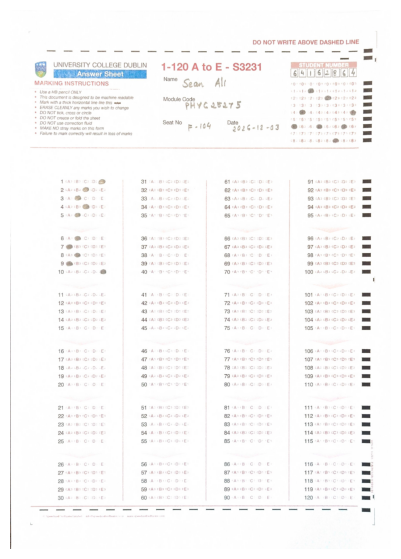

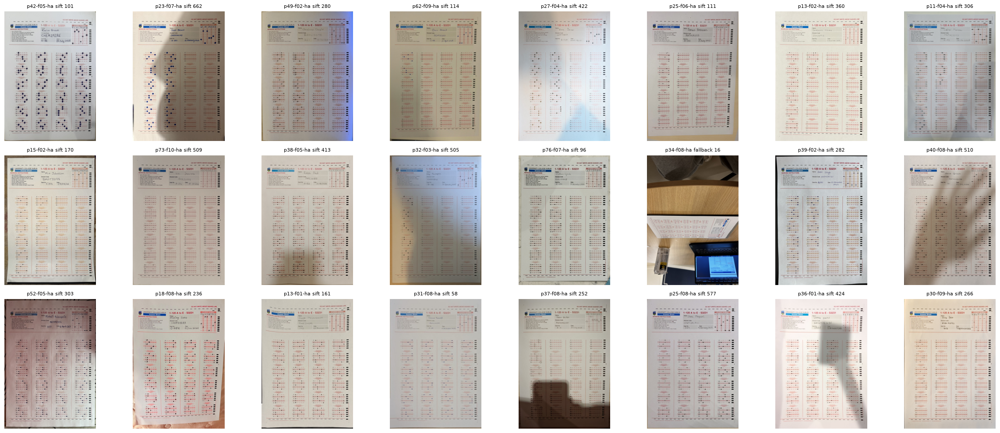

method  fallback  sift
kind                  
hard           1    35
photo          0    40
scan           0    44
median inliers: 306.0 | seconds/image: 0.11


In [6]:
import sys; sys.path.insert(0, "src")
import importlib, align, register
importlib.reload(align); importlib.reload(register)
import cv2, time, numpy as np, pandas as pd, matplotlib.pyplot as plt

sc = main[(main.split == "train") & (main.kind == "scan")].copy()
sc["n_answered"] = sc["n_answered"].astype(int)
ref_row = sc.sort_values("n_answered").iloc[0]
ref_page, _ = align.warp_sheet(cv2.imread(ref_row.path))
cv2.imwrite("Data/template_canonical.png", ref_page)
print("reference:", ref_row.fname, "| n_answered =", ref_row.n_answered)
plt.figure(figsize=(5, 7)); plt.imshow(cv2.cvtColor(ref_page, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.show()

reg = register.Registrar(ref_page)

hard = main[(main.split == "train") & (main.kind == "hard")].sample(24, random_state=0)
fig, axes = plt.subplots(3, 8, figsize=(24, 10))
for ax, (_, r) in zip(axes.ravel(), hard.iterrows()):
    page, info = reg.warp(cv2.imread(r.path))
    ax.imshow(cv2.cvtColor(page, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{r.fname[:10]} {info['method']} {info['inliers']}", fontsize=8)
plt.tight_layout(); plt.show()

samp = main[main.split == "train"].sample(120, random_state=1)
t0, stats = time.time(), []
for _, r in samp.iterrows():
    _, info = reg.warp(cv2.imread(r.path))
    stats.append((r.kind, info["method"], info["inliers"]))
s = pd.DataFrame(stats, columns=["kind", "method", "inliers"])
print(s.groupby(["kind", "method"]).size().unstack(fill_value=0))
print("median inliers:", s.inliers.median(), "| seconds/image:", round((time.time() - t0) / len(samp), 2))

{'n_marks': 42, 'answer_sigma': 1.5, 'digit_sigma': 1.5}


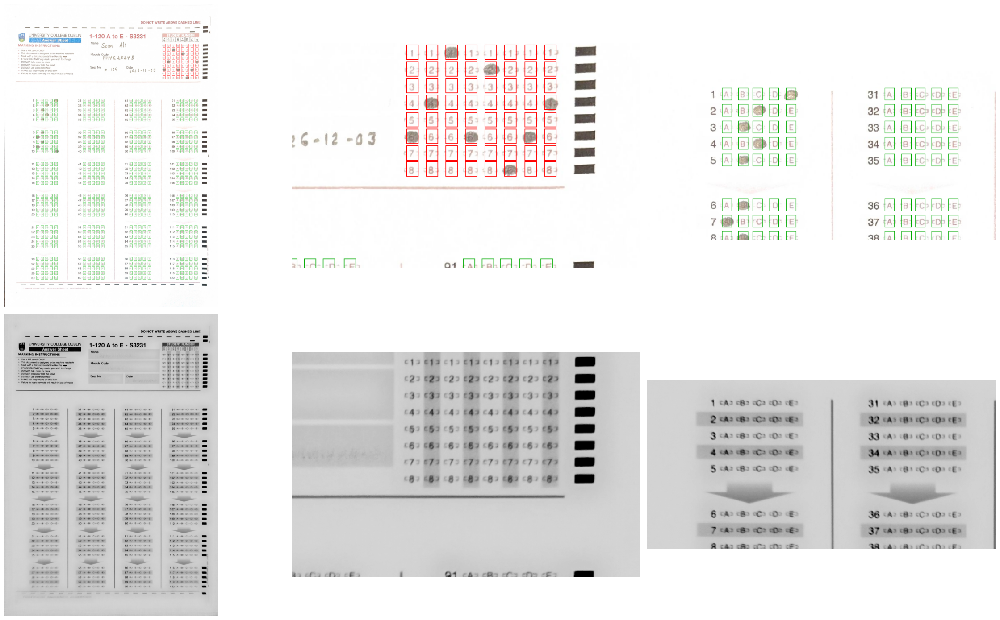

In [7]:
import importlib, grid; importlib.reload(grid)
import cv2, numpy as np, matplotlib.pyplot as plt

samp = main[main.split == "train"].sample(80, random_state=5)
pages = [reg.warp(cv2.imread(p))[0] for p in samp.path]
lay, Rm, Gm = grid.learn_layout(pages, "Data/layout_relearned.json")
print(lay["report"])

if "ans_cols" in lay and lay["ans_cols"]:
    vis = ref_page.copy()
    rx, ry = int(lay["rx"]), int(lay["ry"])
    for y in lay["ans_rows"]:
        for blk in lay["ans_cols"]:
            for x in blk:
                cv2.rectangle(vis, (int(x) - rx, int(y) - ry), (int(x) + rx, int(y) + ry), (0, 170, 0), 1)
    for y in lay["digit_rows"]:
        for x in lay["digit_cols"]:
            cv2.rectangle(vis, (int(x) - rx, int(y) - ry), (int(x) + rx, int(y) + ry), (0, 0, 255), 1)
    crops = [(0, 1754, 0, 1240), (250, 560, 760, 1240), (520, 800, 60, 640)]
    fig, axes = plt.subplots(2, 3, figsize=(24, 14))
    for j, (a, b, c, d) in enumerate(crops):
        axes[0, j].imshow(cv2.cvtColor(vis[a:b, c:d], cv2.COLOR_BGR2RGB)); axes[0, j].axis("off")
        axes[1, j].imshow(Gm[a:b, c:d], cmap="gray", vmin=0.4, vmax=1.1); axes[1, j].axis("off")
    plt.tight_layout(); plt.show()

In [8]:
import sys, json, time, pickle, os
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
sys.path.insert(0, "src")
import importlib, s3231_data, align, register, bubbles
for m in (s3231_data, align, register, bubbles): importlib.reload(m)
from bubbles import bubble_scores, pick_idx, decode, annotate, LETTERS
 
layout = json.load(open("Data/layout.json"))
template = cv2.imread("Data/template_canonical.png")
reg = register.Registrar(template)
main, stress = s3231_data.load_all()
print(main.split.value_counts(dropna=False) if "split" in main else "no split column")

images: 2184 | duplicate filenames dropped: 0 | unparsed filenames: 0 | images without labels: 0
split
train    1249
val       447
test      398
Name: count, dtype: int64


In [9]:
if "split" in main and {"train"} <= set(main.split.dropna()) and (set(main.split.dropna()) - {"train"}):
    main["part"] = np.where(main.split == "train", "train", "test")
else:
    stu = sorted(main.student.unique()); rng = np.random.default_rng(0); rng.shuffle(stu)
    tr = set(stu[: int(0.6 * len(stu))])
    main["part"] = np.where(main.student.isin(tr), "train", "test")
main = main[main.q1.notna()] if "q1" in main else main   # keep only labelled forms
print(main.part.value_counts(), "| stress:", len(stress))
assert not set(main[main.part=="train"].student) & set(main[main.part=="test"].student), "student leakage!"

part
train    1249
test      845
Name: count, dtype: int64 | stress: 90


In [10]:
# %% 3. Run the pipeline (parallel, cached). Registered pages of OUR method are saved to Data/pages
#       so that later feature/threshold changes only need a fast re-score instead of re-registration.
import pipeline, robust; importlib.reload(robust); importlib.reload(pipeline)
N = None      # set N = 20 for a quick dry run
PAGES = "Data/pages"
 
def run(df, variant, name, page_dir=None):
    f = f"Data/cache_{name}.pkl"
    if N is None and os.path.exists(f):
        return pd.read_pickle(f)
    R = pipeline.process_df(df, variant, layout, "Data/template_canonical.png", limit=N, page_dir=page_dir)
    if N is None:
        R.to_pickle(f)
    return R
 
def rescore(df, R_ref):
    """FAST (seconds): re-read the saved registered pages and recompute bubble scores only."""
    R = pipeline.process_df(df, "pages", layout, "Data/template_canonical.png", page_dir=PAGES)
    R["method"] = R_ref.set_index("fname").loc[R.fname].method.values
    return R
 
R_main_plain = run(main,   "sift",   "main_sift_v3")                 # baseline: plain SIFT registration
R_main_b     = run(main,   "align",  "main_align_v3")                # baseline: contour warp only
R_main       = run(main,   "robust", "main_robust_v3", PAGES)        # OURS
R_stress     = run(stress, "robust", "stress_robust_v3", PAGES)
print("methods used:", R_main.method.value_counts().to_dict())

methods used: {'sift': 1926, 'sift2': 96, 'contour': 64, 'fallback': 8}


In [11]:
importlib.reload(bubbles); importlib.reload(pipeline)
from bubbles import bubble_scores, pick_idx, decode, annotate, LETTERS
R_main   = rescore(main, R_main)
R_stress = rescore(stress, R_stress)

pages:   0%|          | 0/2094 [00:00<?, ?it/s]

pages: 2094 forms in 21s with 11 workers, 0 errors


pages:   0%|          | 0/90 [00:00<?, ?it/s]

pages: 90 forms in 4s with 11 workers, 0 errors


In [12]:
def truth_arrays(df):
    T = [s3231_data.truth(r) for _, r in df.iterrows()]
    ta = np.array([[-1 if t["answers"][str(i)] is None else LETTERS.index(t["answers"][str(i)])
                    for i in range(1, 121)] for t in T])
    return ta, [t["student_number"] for t in T]
 
def stack(R, df):
    R = R.set_index("fname").loc[df.fname]
    return np.stack(R.A.values), np.stack(R.D.values)
 
def metrics(A, D, ta, tsn, p):
    pa = pick_idx(A, p["a_abs"], p["a_rel"], p["bg_sub"])
    pd_ = pick_idx(D, p["d_abs"], p["d_rel"], p["bg_sub"])
    psn = [None if (d < 0).any() else "".join(map(str, d)) for d in pd_]
    sn_ok = np.array([a == b for a, b in zip(psn, tsn)])
    q_ok = pa == ta
    return dict(student_number_acc=sn_ok.mean(), per_question_acc=q_ok.mean(),
                exact_form_acc=(sn_ok & q_ok.all(1)).mean()), pa, q_ok, sn_ok

In [13]:
# %% 5. Tune thresholds on TRAIN only: answers and student-number digits are tuned SEPARATELY
tr = main[main.part == "train"]; te = main[main.part == "test"]
A_tr, D_tr = stack(R_main, tr); ta_tr, tsn_tr = truth_arrays(tr)
tsn_arr = np.array([s or "" for s in tsn_tr])

def digits_to_sn(pd_):
    return np.array(["" if (d < 0).any() else "".join(map(str, d)) for d in pd_])

search = {}
for bg in (True, False):
    best_a = best_d = (-1, None)
    for t_abs in np.arange(0.02, 0.40, 0.01):
        for t_rel in (0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
            acc_a = (pick_idx(A_tr, t_abs, t_rel, bg) == ta_tr).mean()
            acc_d = (digits_to_sn(pick_idx(D_tr, t_abs, t_rel, bg)) == tsn_arr).mean()
            if acc_a > best_a[0]: best_a = (acc_a, (float(t_abs), t_rel))
            if acc_d > best_d[0]: best_d = (acc_d, (float(t_abs), t_rel))
    search[bg] = (best_a, best_d)
    print(f"bg_sub={bg}: answers {best_a[0]:.4f} {best_a[1]} | student number {best_d[0]:.4f} {best_d[1]}")

bg = max(search, key=lambda b: search[b][0][0] + search[b][1][0])
(_, (a_abs, a_rel)), (_, (d_abs, d_rel)) = search[bg]
params = dict(a_abs=a_abs, a_rel=float(a_rel), d_abs=d_abs, d_rel=float(d_rel), bg_sub=bg)
print("chosen:", params)
json.dump(params, open("Data/params.json", "w"))      # predict.py loads this automatically 

bg_sub=True: answers 0.8617 (0.039999999999999994, 0.6) | student number 0.8391 (0.02, 0.7)
bg_sub=False: answers 0.8842 (0.02, 0.8) | student number 0.8447 (0.03, 0.9)
chosen: {'a_abs': 0.02, 'a_rel': 0.8, 'd_abs': 0.03, 'd_rel': 0.9, 'bg_sub': False}


In [14]:
ta_te, tsn_te = truth_arrays(te)
ta_st, tsn_st = truth_arrays(stress)
rows = {}
A, D = stack(R_main, te);      rows["SIFT reg + threshold (ours) [test]"] = metrics(A, D, ta_te, tsn_te, params)[0]
A, D = stack(R_main_b, te);    rows["Contour warp only + threshold [test]"] = metrics(A, D, ta_te, tsn_te, params)[0]
naive = dict(a_abs=-1e9, a_rel=1e9, d_abs=-1e9, d_rel=1e9, bg_sub=False)   # plain argmax, never blank
A, D = stack(R_main, te);      rows["SIFT reg + plain argmax [test]"] = metrics(A, D, ta_te, tsn_te, naive)[0]
A, D = stack(R_stress, stress); rows["SIFT reg + threshold (ours) [stress]"] = metrics(A, D, ta_st, tsn_st, params)[0]
res = pd.DataFrame(rows).T.round(4)
res["sec_per_form"] = [R_main.t_total[R_main.fname.isin(te.fname)].mean(),
                       R_main_b.t_total[R_main_b.fname.isin(te.fname)].mean(),
                       R_main.t_total[R_main.fname.isin(te.fname)].mean(),
                       R_stress.t_total.mean()]
display(res)

,student_number_acc,per_question_acc,exact_form_acc,sec_per_form
SIFT reg + threshold (ours) [test],0.9089,0.8946,0.1728,0.086833
Contour warp only + threshold [test],0.1822,0.4768,0.0000,0.193497
SIFT reg + plain argmax [test],0.8284,0.4553,0.0000,0.086833
SIFT reg + threshold (ours) [stress],0.2556,0.8494,0.0444,0.094060


In [15]:
A, D = stack(R_main_plain, te)
print("plain SIFT, no verification:", metrics(A, D, ta_te, tsn_te, params)[0])

plain SIFT, no verification: {'student_number_acc': np.float64(0.5715976331360947), 'per_question_acc': np.float64(0.5553648915187377), 'exact_form_acc': np.float64(0.0)}


In [16]:
m, pa, q_ok, sn_ok = metrics(*stack(R_main, te), ta_te, tsn_te, params)
te2 = te.reset_index(drop=True).assign(q_acc=q_ok.mean(1), sn_ok=sn_ok, exact=sn_ok & q_ok.all(1))
te2["method"] = R_main.set_index("fname").loc[te2.fname].method.values
display(te2.groupby("kind")[["q_acc", "sn_ok", "exact"]].mean().round(3).assign(n=te2.groupby("kind").size()))
display(te2.groupby("method")[["q_acc", "sn_ok", "exact"]].mean().round(3).assign(n=te2.groupby("method").size()))

,q_acc,sn_ok,exact,n
kind,,,,
hard,0.864,0.857,0.140,286
photo,0.879,0.921,0.196,280
scan,0.942,0.950,0.183,279


,q_acc,sn_ok,exact,n
method,,,,
contour,0.503,0.500,0.000,20
fallback,0.225,0.000,0.000,3
sift,0.907,0.926,0.178,780
sift2,0.906,0.857,0.167,42


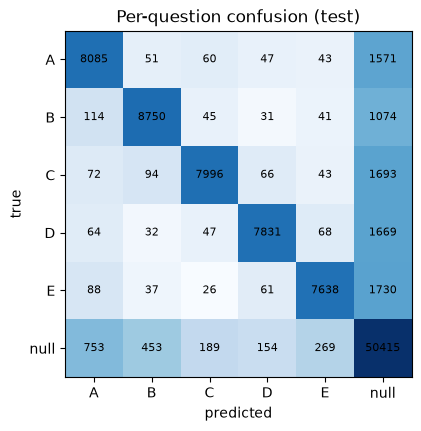

In [17]:
pa_ = np.where(pa < 0, 5, pa).ravel(); ta_ = np.where(ta_te < 0, 5, ta_te).ravel()
cm = np.zeros((6, 6), int); np.add.at(cm, (ta_, pa_), 1)
labels = list(LETTERS) + ["null"]
plt.figure(figsize=(5, 4.5)); plt.imshow(np.log1p(cm), cmap="Blues")
for i in range(6):
    for j in range(6): plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
plt.xticks(range(6), labels); plt.yticks(range(6), labels)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Per-question confusion (test)"); plt.show()

In [18]:
import subprocess, tempfile
t = []
for p in te.path.head(5):
    out = tempfile.mktemp(suffix=".json"); t0 = time.perf_counter()
    subprocess.run([sys.executable, "predict.py", "--input", p, "--output", out], check=True)
    t.append(time.perf_counter() - t0); json.load(open(out))
print("predict.py CLI (incl. Python/OpenCV start-up): %.2fs/form, CPU only, no GPU used" % np.mean(t))

predict.py CLI (incl. Python/OpenCV start-up): 1.42s/form, CPU only, no GPU used


In [19]:
A_te, D_te = stack(R_main, te)
ta_te, tsn_te = truth_arrays(te)
pa = pick_idx(A_te, params["a_abs"], params["a_rel"], params["bg_sub"])
miss  = ((ta_te>=0) & (pa<0)).sum(1)
fp    = ((ta_te<0)  & (pa>=0)).sum(1)
wrong = ((ta_te>=0) & (pa>=0) & (pa!=ta_te)).sum(1)
d = te.reset_index(drop=True).assign(miss=miss, fp=fp, wrong=wrong)
print(d[["miss","fp","wrong"]].describe().round(1))
print(d.sort_values("miss", ascending=False)[["fname","kind","miss","fp","wrong"]].head(15))
print("share of all misses in the worst 10% of forms:", round(np.sort(miss)[::-1][:len(miss)//10].sum()/miss.sum(), 3))

        miss     fp  wrong
count  845.0  845.0  845.0
mean     9.2    2.2    1.3
std     16.9    5.1    5.0
min      0.0    0.0    0.0
25%      0.0    0.0    0.0
50%      1.0    1.0    0.0
75%     10.0    2.0    0.0
max    103.0   70.0   51.0
                 fname   kind  miss  fp  wrong
282  p02-f01-photo.jpg  photo   103   1      0
570   p02-f01-hard.jpg   hard   102   1      0
387   p26-f05-scan.jpg   scan    96   0      0
347   p17-f08-hard.jpg   hard    93   1      0
635  p17-f08-photo.jpg  photo    93   2     12
586  p05-f08-photo.jpg  photo    89   0      1
402  p35-f08-photo.jpg  photo    89   0      3
28    p05-f08-hard.jpg   hard    87   0      1
241   p66-f05-hard.jpg   hard    85   0     21
521  p66-f05-photo.jpg  photo    80   2      0
337   p16-f05-hard.jpg   hard    80   0      0
427   p45-f05-hard.jpg   hard    77   6     26
590  p06-f05-photo.jpg  photo    73   0      0
498   p60-f01-hard.jpg   hard    72   1      0
809   p66-f08-hard.jpg   hard    72   1      0
share

In [20]:
def sn_report(R, df, tsn, name):
    A, D = stack(R, df)
    dg = pick_idx(D, params["d_abs"], params["d_rel"], params["bg_sub"])      # (N, 8), -1 = blank
    lab = np.array([s or "" for s in tsn]); ok = np.array([len(s) == 8 for s in lab])
    L = np.array([[int(c) for c in s] if len(s) == 8 else [-9]*8 for s in lab])
    has9 = ok & np.array(["9" in s for s in lab])
    print(f"--- {name}: valid labels {ok.mean():.3f} | exact SN acc on valid {(dg[ok]==L[ok]).all(1).mean():.3f}")
    print("per-column acc  :", (dg[ok]==L[ok]).mean(0).round(3))
    print("blank-read rate :", (dg[ok]<0).mean(0).round(3))
    print("labels containing a 9:", int(has9.sum()), "| acc on them:", (dg[has9]==L[has9]).all(1).mean().round(3) if has9.any() else "n/a")
sn_report(R_main, te, tsn_te, "test"); sn_report(R_stress, stress, tsn_st, "stress")

--- test: valid labels 0.878 | exact SN acc on valid 0.914
per-column acc  : [0.962 0.947 0.961 0.953 0.961 0.964 0.962 0.958]
blank-read rate : [0.018 0.027 0.02  0.026 0.02  0.016 0.022 0.019]
labels containing a 9: 0 | acc on them: n/a
--- stress: valid labels 0.900 | exact SN acc on valid 0.210
per-column acc  : [0.444 0.568 0.543 0.469 0.481 0.358 0.494 0.494]
blank-read rate : [0.148 0.074 0.123 0.111 0.099 0.111 0.111 0.123]
labels containing a 9: 0 | acc on them: n/a


In [21]:
def norm_scores(S):
    f = S.reshape(len(S), -1)
    bgl = np.median(f, axis=1); hi = np.percentile(f, 95, axis=1)
    return (S - bgl[:, None, None]) / np.maximum(hi - bgl, 1e-3)[:, None, None]

tr = main[main.part == "train"]
A_tr, D_tr = stack(R_main, tr); ta_tr, tsn_tr = truth_arrays(tr)
An_tr, An_te = norm_scores(A_tr), norm_scores(A_te)
best = (-1, None)
for t_abs in np.arange(0.05, 0.8, 0.025):
    for t_rel in np.arange(0.4, 0.96, 0.05):
        acc = (pick_idx(An_tr, t_abs, t_rel, False) == ta_tr).mean()
        if acc > best[0]: best = (acc, (round(float(t_abs), 3), round(float(t_rel), 2)))
print("normalised, train:", best)
t_abs, t_rel = best[1]
print("normalised, TEST :", (pick_idx(An_te, t_abs, t_rel, False) == ta_te).mean().round(4), "| current:", (pa == ta_te).mean().round(4))

normalised, train: (np.float64(0.853869762476648), (0.4, 0.55))
normalised, TEST : 0.8657 | current: 0.8946


In [22]:
def show(fname, ax, title):
    r = pd.concat([main, stress]).set_index("fname").loc[fname]
    page, _ = reg.warp(cv2.imread(r.path))
    A, D = bubble_scores(page, layout)
    sn, ans = decode(A, D, params)
    img = annotate(page, layout, ans, sn)
    img = img[int(0.26 * img.shape[0]):]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(title, fontsize=9)

               fname   kind  n_marks  ink_marked  ink_blank    AUC
0  p02-f01-photo.jpg  photo      114       0.243      0.203  0.852
1   p02-f01-hard.jpg   hard      114       0.192      0.159  0.893
2   p26-f05-scan.jpg   scan      118       0.204      0.166  0.900
3   p17-f08-hard.jpg   hard      114       0.180      0.142  0.834
4  p17-f08-photo.jpg  photo      114       0.141      0.128  0.577
5  p05-f08-photo.jpg  photo      111       0.124      0.108  0.674
6  p35-f08-photo.jpg  photo      114       0.202      0.170  0.710
7   p05-f08-hard.jpg   hard      111       0.178      0.139  0.810
8   p66-f05-hard.jpg   hard      112       0.122      0.112  0.537
9  p66-f05-photo.jpg  photo      112       0.214      0.168  0.866


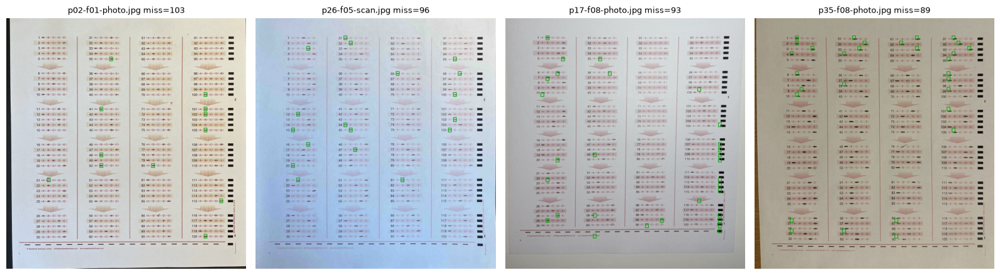

In [23]:
def auc_form(i):
    m = np.zeros((120, 5), bool); q = np.where(ta_te[i] >= 0)[0]; m[q, ta_te[i][q]] = True
    pos, neg = A_te[i][m], A_te[i][~m]
    return len(pos), np.median(pos), np.median(neg), (pos[:, None] > neg[None, :]).mean()
worst = d.sort_values("miss", ascending=False).index[:10]
print(pd.DataFrame([(d.fname[i], d.kind[i], *auc_form(i)) for i in worst],
      columns=["fname", "kind", "n_marks", "ink_marked", "ink_blank", "AUC"]).round(3))
fig, axes = plt.subplots(1, 4, figsize=(16, 7))
for ax, i in zip(axes, worst[[0, 2, 4, 6]]): show(d.fname[i], ax, f"{d.fname[i]} miss={d.miss[i]}")
plt.tight_layout(); plt.show()

In [24]:
def otsu(v, bins=64):
    h, e = np.histogram(v, bins=bins); p = h / h.sum(); c = (e[:-1] + e[1:]) / 2
    w0 = np.cumsum(p); w1 = 1 - w0; cm = np.cumsum(p * c); mt = cm[-1]
    var = w0 * w1 * (cm / np.maximum(w0, 1e-9) - (mt - cm) / np.maximum(w1, 1e-9)) ** 2
    return c[np.argmax(var)]
def pick_form(S, thr, t_rel):
    s2 = np.sort(S, -1); top, sec = s2[..., -1], s2[..., -2]
    return np.where((top >= thr[:, None]) & (sec <= t_rel * top), S.argmax(-1), -1)

O_tr = np.array([otsu(x) for x in A_tr.max(-1)]); O_te = np.array([otsu(x) for x in A_te.max(-1)])
best = (-1, None)
for floor in (0.01, 0.02, 0.03, 0.05):
    for w in np.arange(0.3, 1.01, 0.1):
        for t_rel in (0.6, 0.7, 0.8, 0.9):
            acc = (pick_form(A_tr, np.maximum(floor, w * O_tr), t_rel) == ta_tr).mean()
            if acc > best[0]: best = (acc, (floor, round(float(w), 1), t_rel))
print("per-form Otsu, train:", round(best[0], 4), best[1])
fl, w, tr_ = best[1]
pf = pick_form(A_te, np.maximum(fl, w * O_te), tr_)
print("per-form Otsu, TEST :", (pf == ta_te).mean().round(4), "| current:", (pa == ta_te).mean().round(4))

per-form Otsu, train: 0.8857 (0.05, 0.8, 0.9)
per-form Otsu, TEST : 0.8984 | current: 0.8946


In [25]:
sub = te.head(20); ta, tsn = truth_arrays(sub); accs, sns = [], []
for k, (_, r) in enumerate(sub.iterrows()):
    out = tempfile.mktemp(suffix=".json")
    subprocess.run([sys.executable, "predict.py", "--input", r.path, "--output", out], check=True)
    P = json.load(open(out))
    pred = np.array([-1 if P["answers"][str(i)] is None else LETTERS.index(P["answers"][str(i)]) for i in range(1, 121)])
    accs.append((pred == ta[k]).mean()); sns.append((P["student_number"] or "") == (tsn[k] or ""))
print("CLI per-question:", np.mean(accs).round(3), "| CLI student number:", np.mean(sns))

CLI per-question: 0.96 | CLI student number: 1.0


In [26]:
main.part.value_counts()

part
train    1249
test      845
Name: count, dtype: int64

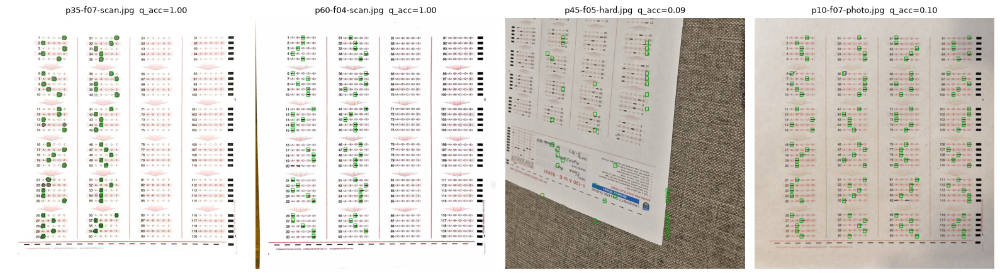

In [27]:
def show_crop(fname, ax, title):
    r = pd.concat([main, stress]).set_index("fname").loc[fname]
    page, _ = reg.warp(cv2.imread(r.path))
    A, D = bubble_scores(page, layout)
    sn, ans = decode(A, D, params)
    img = annotate(page, layout, ans, sn)
    img = img[int(0.26 * img.shape[0]):]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(title, fontsize=9)

order = te2.sort_values("q_acc")
fig, axes = plt.subplots(1, 4, figsize=(16, 7))
for ax, (_, r) in zip(axes, pd.concat([order.tail(2), order.head(2)]).iterrows()):
    show_crop(r.fname, ax, f"{r.fname}  q_acc={r.q_acc:.2f}")
plt.tight_layout()
fig.savefig("fig_examples.pdf", bbox_inches="tight", dpi=200)
plt.show()